In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets
from torchvision.transforms import v2
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo activo: {device}")


Dispositivo activo: cuda


In [ ]:

# Transformación limpia: a Tensor y escalado [0.0, 1.0]
transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True)
])

# Descarga y DataLoaders (usamos FashionMNIST como ejemplo)
train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

#train_dataset = datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)
#test_dataset = datasets.FashionMNIST(root='./data', train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.18MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 135kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.29MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 11.3MB/s]


In [ ]:
class AutoencoderDenso(nn.Module):
    def __init__(self):
        super().__init__()

        # --- COMPONENTES DEL ENCODER ---
        # A diferencia de la CNN, aplanamos la imagen inmediatamente al entrar
        self.aplanar = nn.Flatten()

        # Capas densas (Fully Connected) de compresión progresiva
        self.fc_encoder1 = nn.Linear(in_features=28 * 28, out_features=256)
        self.relu1 = nn.ReLU()

        self.fc_encoder2 = nn.Linear(in_features=256, out_features=128)
        self.relu2 = nn.ReLU()

        # Cuello de botella: proyecta al espacio latente de 64D
        self.fc_encoder3 = nn.Linear(in_features=128, out_features=64)

        # --- COMPONENTES DEL DECODER ---
        # Capas densas de expansión progresiva
        self.fc_decoder1 = nn.Linear(in_features=64, out_features=128)
        self.relu3 = nn.ReLU()

        self.fc_decoder2 = nn.Linear(in_features=128, out_features=256)
        self.relu4 = nn.ReLU()

        # Proyecta de nuevo a la cantidad total de píxeles originales (784)
        self.fc_decoder3 = nn.Linear(in_features=256, out_features=28 * 28)
        self.sigmoid = nn.Sigmoid()

        # Restauramos la topología 2D para que la salida vuelva a ser una imagen
        self.desaplanar = nn.Unflatten(dim=1, unflattened_size=(1, 28, 28))

    def encode(self, x):
        """Transforma la imagen 2D en un vector latente de 64D."""
        x = self.aplanar(x)     # [batch, 1, 28, 28] -> [batch, 784]

        x = self.fc_encoder1(x)         # [batch, 784] -> [batch, 256]
        x = self.relu1(x)

        x = self.fc_encoder2(x)         # [batch, 256] -> [batch, 128]
        x = self.relu2(x)

        z = self.fc_encoder3(x)  # [batch, 128] -> [batch, 64]
        return z

    def decode(self, z):
        """Reconstruye los píxeles a partir del vector latente."""
        x = self.fc_decoder1(z) # [batch, 64] -> [batch, 128]
        x = self.relu3(x)

        x = self.fc_decoder2(x) # [batch, 128] -> [batch, 256]
        x = self.relu4(x)

        x = self.fc_decoder3(x) # [batch, 256] -> [batch, 784]
        x = self.sigmoid(x)     # Escala píxeles al rango [0.0, 1.0]

        x = self.desaplanar(x)  # [batch, 784] -> [batch, 1, 28, 28]
        return x

    def forward(self, x):
        """Flujo orquestado: imagen original -> vector latente -> imagen reconstruida."""
        z = self.encode(x)
        x_recon = self.decode(z)
        return x_recon

# Instanciamos el modelo y lo enviamos a la GPU
modelo_denso = AutoencoderDenso().to(device)
print(modelo_denso)

AutoencoderDenso(
  (aplanar): Flatten(start_dim=1, end_dim=-1)
  (fc_encoder1): Linear(in_features=784, out_features=256, bias=True)
  (relu1): ReLU()
  (fc_encoder2): Linear(in_features=256, out_features=128, bias=True)
  (relu2): ReLU()
  (fc_encoder3): Linear(in_features=128, out_features=64, bias=True)
  (fc_decoder1): Linear(in_features=64, out_features=128, bias=True)
  (relu3): ReLU()
  (fc_decoder2): Linear(in_features=128, out_features=256, bias=True)
  (relu4): ReLU()
  (fc_decoder3): Linear(in_features=256, out_features=784, bias=True)
  (sigmoid): Sigmoid()
  (desaplanar): Unflatten(dim=1, unflattened_size=(1, 28, 28))
)


In [ ]:
# Usamos MSELoss para medir la diferencia de píxel a píxel
criterion = nn.MSELoss()
optimizer = optim.Adam(modelo_denso.parameters(), lr=0.001)

epochs = 10
print("Iniciando entrenamiento del Autoencoder Denso...\n")

for epoch in range(epochs):
    modelo_denso.train()
    perdida_total = 0.0

    for images, _ in train_loader: # Ignoramos las labels (el _)
        images = images.to(device)

        optimizer.zero_grad()
        # Pasamos la imagen y obtenemos la reconstrucción
        reconstruccion = modelo_denso(images)

        # La pérdida es la diferencia entre la imagen original y la reconstrucción
        loss = criterion(reconstruccion, images)
        loss.backward()
        optimizer.step()

        perdida_total += loss.item()

    perdida_media = perdida_total / len(train_loader)
    print(f"Epoch {epoch+1}/{epochs} | Loss de Reconstrucción (MSE): {perdida_media:.4f}")

Iniciando entrenamiento del Autoencoder Denso...

Epoch 1/10 | Loss de Reconstrucción (MSE): 0.0400
Epoch 2/10 | Loss de Reconstrucción (MSE): 0.0186
Epoch 3/10 | Loss de Reconstrucción (MSE): 0.0138
Epoch 4/10 | Loss de Reconstrucción (MSE): 0.0115
Epoch 5/10 | Loss de Reconstrucción (MSE): 0.0099
Epoch 6/10 | Loss de Reconstrucción (MSE): 0.0089
Epoch 7/10 | Loss de Reconstrucción (MSE): 0.0082
Epoch 8/10 | Loss de Reconstrucción (MSE): 0.0076
Epoch 9/10 | Loss de Reconstrucción (MSE): 0.0071
Epoch 10/10 | Loss de Reconstrucción (MSE): 0.0067


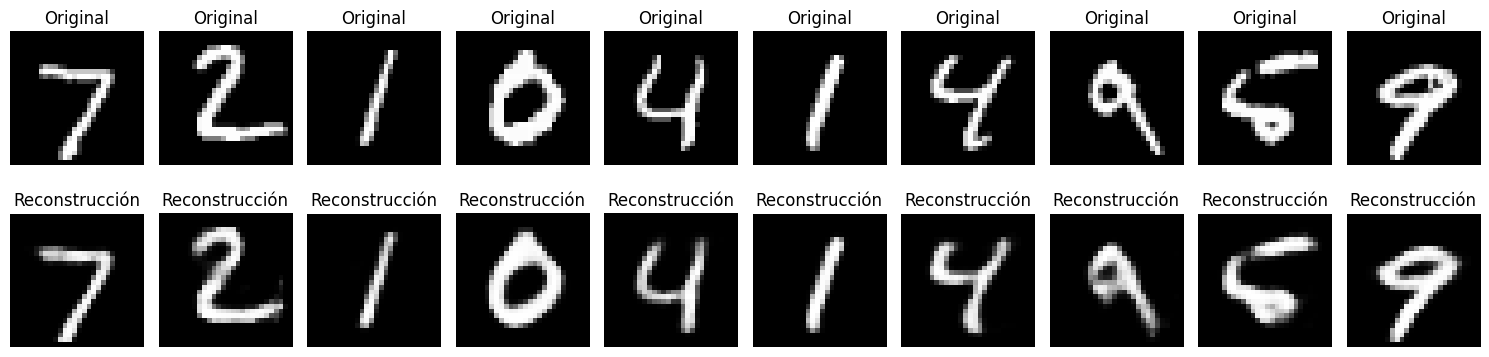

In [ ]:
def visualizar_reconstrucciones(modelo, dataloader, device, num_imagenes=10):
    modelo.eval()

    # Obtenemos un solo lote
    images, _ = next(iter(dataloader))
    images = images.to(device)

    with torch.no_grad():
        reconstrucciones = modelo(images)

    # Movemos a CPU para matplotlib
    images = images.cpu() # Es equivalente a images = images.to(torch.device("cpu"))
    reconstrucciones = reconstrucciones.cpu()

    fig, axes = plt.subplots(2, num_imagenes, figsize=(15, 4))

    for i in range(num_imagenes):
        # Fila superior: Originales
        axes[0, i].imshow(images[i].squeeze(), cmap='gray')
        axes[0, i].set_title("Original")
        axes[0, i].axis('off')

        # Fila inferior: Reconstrucciones
        axes[1, i].imshow(reconstrucciones[i].squeeze(), cmap='gray')
        axes[1, i].set_title("Reconstrucción")
        axes[1, i].axis('off')

    plt.tight_layout()
    plt.show()

visualizar_reconstrucciones(modelo_denso, test_loader, device)